# Comparación de modelos — IC por bootstrap

Notebook **reutilizable** para comparar modelos por sus métricas de validación
con intervalos de confianza (bootstrap *cluster* a nivel línea).

1. **Errorbar**: punto ± IC95% por métrica — la vista *fiel* al IC del bootstrap.
2. **Boxplot** con bigotes en los percentiles 2.5/97.5 (= el IC95%) + cuartiles.

In [1]:
import os
import sys
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Detectar la raíz del repo (donde vive src/) y pararse ahí: así los paths
# relativos de los configs (data/..., configs/...) resuelven como en train.py.
ROOT = pathlib.Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.training.save_model import (
    load_cached_results,
    results_cache_key,
    save_cached_results,
)
from src.training.run import run_evaluation
from src.utils.config import load_config
from src.utils.seed import set_seed

print("repo root:", ROOT)

repo root: c:\Users\MODDE\Desktop\Udesa\ML\PF\maze-genomic-pred


In [2]:
# === Modelos a comparar =====================================================
# Baseline GBLUP sin PCA, y DOS formas de elegir la dim de PCA (para ver cómo el
# método de selección cambia la conclusión):
#   (A) del SWEEP de wandb -> dim que maximiza Pearson en val 2019 (el MISMO set
#       donde después comparás): es lo estándar, pero el número del ganador queda
#       OPTIMISTA (winner's curse).
#   (B) ANIDADA -> dim elegida en un inner-val ANTERIOR (2018, train 2017) sin
#       tocar 2019: comparación honesta. Solo dims < ~900 (techo de rango p≫n).
from src.training.sweep import best_config_from_sweep, best_run_from_sweep
from src.training.select import config_with_nested_dim

SWEEP_PATH  = "oromagnoli-/maze-genomic-pred/ziu59tim"   # sweep de dim de PCA (split fijo)
PCA_BASE    = "configs/exp_pca_gblup_2017_2018_to_2019.yaml"
DIM_KEY     = "preprocess.pca.n_components"
NESTED_DIMS = [16, 32, 64, 128, 256, 512]                # elegibles en inner-2018 (n=901)

CONFIGS = {"GBLUP sin PCA (REML)": "configs/exp_gblup_2017_2018_to_2019.yaml"}

# (A) mejor del sweep — selección sobre val 2019 (OPTIMISTA)
try:
    ov, best_val, rid = best_run_from_sweep(SWEEP_PATH)
    a_dim = ov.get(DIM_KEY, "?")
    print(f"(A) sweep   -> dim={a_dim}  pearson_r_mean(val 2019)={best_val:.4f}  (run {rid})  [OPTIMISTA]")
    CONFIGS[f"PCA-{a_dim} (elegida en 2019)"] = best_config_from_sweep(SWEEP_PATH, PCA_BASE)
except Exception as e:
    print(f"[warn] no pude leer el sweep ({e}); salteo la opción (A)")

# (B) selección anidada — inner-val 2018, no toca 2019 (HONESTA)
cfg_nested, sel = config_with_nested_dim(PCA_BASE, DIM_KEY, NESTED_DIMS, inner_val_year=2018)
scores_2018 = {k: round(v, 3) for k, v in sel["scores"].items()}
print(f"(B) anidada -> dim={sel['best']}  (mejor en inner-2018; scores={scores_2018})  [HONESTA]")
CONFIGS[f"PCA-{sel['best']} (elegida en 2018)"] = cfg_nested

METRICS = ("pearson_r", "rmse", "r2")   # portada primero
N_BOOT = 2000      # réplicas de bootstrap (más = IC más estable)
ALPHA = 0.05       # IC del (1-alpha); 0.05 -> IC 95% (percentiles 2.5 / 97.5)

# Evita reentrenar modelos si ya hay resultados cacheados
USE_CACHE = True

FIG_DIR = ROOT / "experiments" / "figs"   
FIG_DIR.mkdir(parents=True, exist_ok=True)

wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from C:\Users\MODDE\.netrc.


(A) sweep   -> dim=1000  pearson_r_mean(val 2019)=0.3402  (run x00g6302)  [OPTIMISTA]
(B) anidada -> dim=128  (mejor en inner-2018; scores={16: 0.331, 32: 0.22, 64: 0.327, 128: 0.378, 256: 0.342, 512: 0.234})  [HONESTA]


In [3]:
import copy

def evaluate_model(name, config, *, n_boot=N_BOOT, alpha=ALPHA, use_cache=USE_CACHE):
    '''Corre run_evaluation (sin wandb) con bootstrap forzado y devuelve:
       - filas tidy [{model, metric, point, lo, hi}]
       - dict {metric: samples} con la distribución bootstrap por métrica.
    `config` puede ser una RUTA a un YAML o un dict de config ya armado (p.ej. el
    que devuelve best_config_from_sweep). Asume split fijo (un único fold de val).

    Con use_cache=True NO reentrena si ya hay resultados cacheados para esta
    (config, seed, n_boot, alpha): los levanta de disco. En miss evalúa y guarda.'''
    cfg = load_config(config) if isinstance(config, str) else copy.deepcopy(config)
    set_seed(int(cfg.get("seed", 575)))
    cfg.setdefault("bootstrap", {})
    cfg["bootstrap"].update(enabled=True, n_boot=n_boot, alpha=alpha)  # IC siempre on

    key = results_cache_key(cfg, n_boot=n_boot, alpha=alpha)
    res = load_cached_results(key) if use_cache else None
    if res is None:
        res = run_evaluation(cfg)              # sin log_fn => no toca wandb
        save_cached_results(key, res)          # cachea para las próximas corridas
    else:
        print(f"  [cache hit] {name} ({key})")

    fold = res["per_fold"][-1]                 # split fijo: el (único) fold de val
    boot = res["bootstrap"][-1] if res["bootstrap"] else {}

    rows, samples = [], {}
    for m in METRICS:
        rows.append({
            "model": name, "metric": m,
            "point": float(fold.get(m, np.nan)),
            "lo": float(fold.get(f"{m}_lo", np.nan)),
            "hi": float(fold.get(f"{m}_hi", np.nan)),
        })
        samples[m] = np.asarray(boot.get(m, []), dtype=float)
    return rows, samples

In [4]:
rows, samples_by_model = [], {}
for name, path in CONFIGS.items():
    r, s = evaluate_model(name, path)
    rows.extend(r)
    samples_by_model[name] = s
    print(f"[ok] {name}")

df = pd.DataFrame(rows)
df

  [cache hit] GBLUP sin PCA (REML) (90f1d6fe13802d36)
[ok] GBLUP sin PCA (REML)
  [cache hit] PCA-1000 (elegida en 2019) (2f368b7b9e73e0ec)
[ok] PCA-1000 (elegida en 2019)
  [cache hit] PCA-128 (elegida en 2018) (d60b0cec807a233b)
[ok] PCA-128 (elegida en 2018)


,model,metric,point,lo,hi
0,GBLUP sin PCA (REML),pearson_r,0.314528,0.246174,0.377771
1,GBLUP sin PCA (REML),rmse,1.301634,1.239727,1.363143
2,GBLUP sin PCA (REML),r2,-0.664404,-0.873739,-0.490156
3,PCA-1000 (elegida en 2019),pearson_r,0.340193,0.274056,0.403527
4,PCA-1000 (elegida en 2019),rmse,1.301215,1.236220,1.364775
5,PCA-1000 (elegida en 2019),r2,-0.663332,-0.878916,-0.485362
6,PCA-128 (elegida en 2018),pearson_r,0.245375,0.180659,0.306936
7,PCA-128 (elegida en 2018),rmse,1.311948,1.250326,1.369933
8,PCA-128 (elegida en 2018),r2,-0.690886,-0.876803,-0.537228


In [5]:
# === Test PAREADO de la diferencia vs la REFERENCIA (modelo[0] = baseline) =====
# Comparar dos boxplots marginales NO dice si A le gana a B: se solapan por el
# ruido COMPARTIDO de qué líneas caen en val (afecta a los dos igual). Lo correcto
# es la diferencia sobre el MISMO resample: run_evaluation corre el bootstrap de
# cada modelo con la misma seed y el mismo grupo de líneas, así
# samples_X[b] - samples_ref[b] es un bootstrap PAREADO válido (ese ruido se
# cancela). Referencia = 1er modelo (baseline); comparamos cada otro contra él.
ref = list(samples_by_model)[0]
qlo, qhi = 100 * ALPHA / 2, 100 * (1 - ALPHA / 2)
for name in list(samples_by_model)[1:]:
    print(f"\n{name}  -  {ref}:")
    for m in METRICS:
        sx, sr = samples_by_model[name][m], samples_by_model[ref][m]
        n = min(len(sx), len(sr))
        d = (sx[:n] - sr[:n]); d = d[np.isfinite(d)]
        lo, hi = np.nanpercentile(d, [qlo, qhi])
        sig = "SIGNIFICATIVA" if (lo > 0 or hi < 0) else "no significativa (IC incluye 0)"
        print(f"  {m:>9}: delta = {np.mean(d):+.4f}  IC95% [{lo:+.4f}, {hi:+.4f}]  -> {sig}")
print("\nOJO: la dim 'elegida en 2019' se seleccionó sobre ESTE mismo val 2019 -> su "
      "delta es un techo OPTIMISTA (post-selección). La 'elegida en 2018' es la "
      "comparación honesta. La adjudicación final es 2020, sellado.")


PCA-1000 (elegida en 2019)  -  GBLUP sin PCA (REML):
  pearson_r: delta = +0.0255  IC95% [+0.0025, +0.0489]  -> SIGNIFICATIVA
       rmse: delta = -0.0002  IC95% [-0.0230, +0.0216]  -> no significativa (IC incluye 0)
         r2: delta = +0.0004  IC95% [-0.0560, +0.0589]  -> no significativa (IC incluye 0)

PCA-128 (elegida en 2018)  -  GBLUP sin PCA (REML):
  pearson_r: delta = -0.0689  IC95% [-0.1022, -0.0369]  -> SIGNIFICATIVA
       rmse: delta = +0.0102  IC95% [-0.0175, +0.0372]  -> no significativa (IC incluye 0)
         r2: delta = -0.0259  IC95% [-0.0941, +0.0451]  -> no significativa (IC incluye 0)

OJO: la dim 'elegida en 2019' se seleccionó sobre ESTE mismo val 2019 -> su delta es un techo OPTIMISTA (post-selección). La 'elegida en 2018' es la comparación honesta. La adjudicación final es 2020, sellado.


## 1) Errorbar — punto ± IC95%

La forma más fiel de mostrar el IC: el punto es la estimación sobre validación y
los bigotes son los percentiles 2.5 / 97.5 del bootstrap. Ideal para comparar
varios modelos de un vistazo.

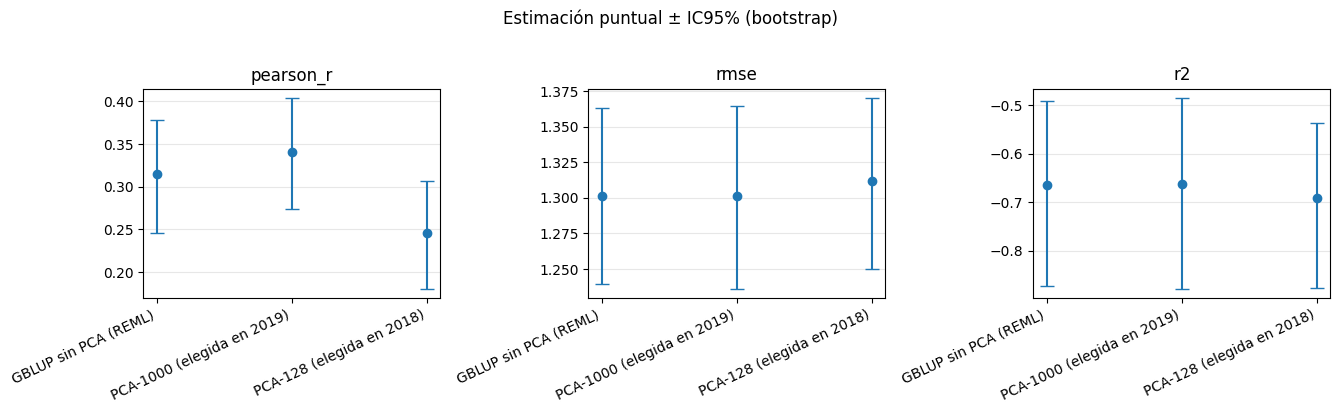

In [6]:
def plot_ci(df, metrics=METRICS, title="Estimación puntual ± IC95% (bootstrap)"):
    '''Un subplot por métrica; cada modelo como punto con bigotes [lo, hi].'''
    fig, axes = plt.subplots(1, len(metrics), figsize=(4.5 * len(metrics), 4))
    axes = np.atleast_1d(axes)
    for ax, m in zip(axes, metrics):
        sub = df[df.metric == m].reset_index(drop=True)
        x = np.arange(len(sub))
        point = sub["point"].to_numpy(float)
        lo = sub["lo"].to_numpy(float)
        hi = sub["hi"].to_numpy(float)
        # yerr no-negativo (el punto puede caer fuera del IC en distros sesgadas).
        yerr = np.vstack([np.maximum(point - lo, 0), np.maximum(hi - point, 0)])
        ax.errorbar(x, point, yerr=yerr, fmt="o", capsize=5, lw=1.5, color="tab:blue")
        ax.set_xticks(x)
        ax.set_xticklabels(sub["model"], rotation=25, ha="right")
        ax.set_title(m)
        ax.grid(True, axis="y", alpha=0.3)
    fig.suptitle(title, y=1.02, fontsize=12)
    fig.tight_layout()
    return fig


fig = plot_ci(df)
fig.savefig(FIG_DIR / "ci_errorbars.png", dpi=150, bbox_inches="tight")
plt.show()

## 2) Boxplot de la distribución bootstrap

Un boxplot por default pone los bigotes en 1.5·IQR, que **no** es tu IC. El truco:
`whis=(2.5, 97.5)` deja los bigotes exactamente en el **IC95%**. La caja sigue
mostrando los cuartiles (Q1 / mediana / Q3), así ves forma + IC juntos.
(Pearson del dummy es `nan` → se saltea solo.)

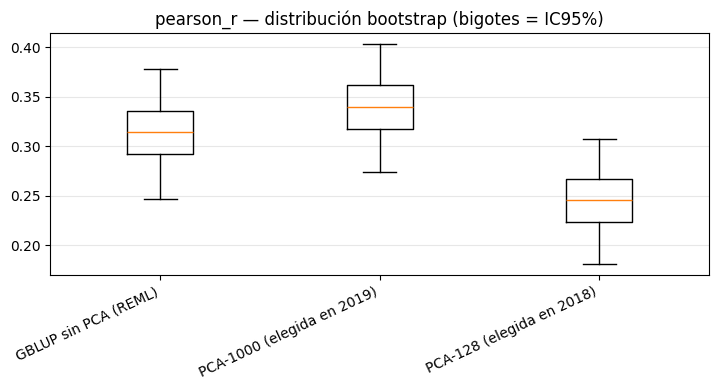

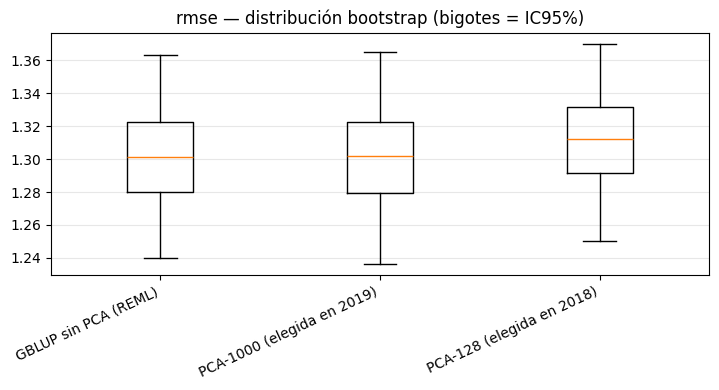

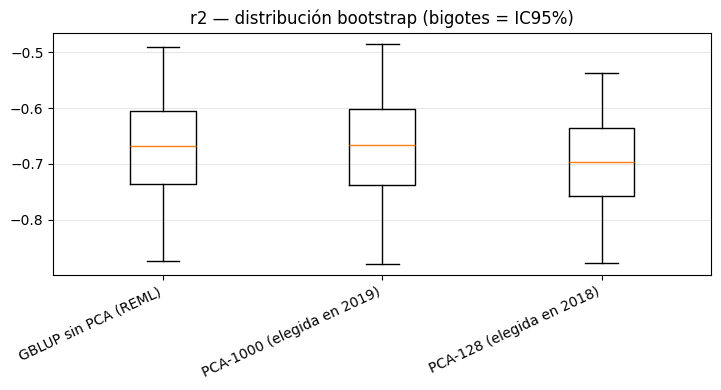

In [7]:
def plot_box(samples_by_model, metric, *, whis=(2.5, 97.5)):
    '''Boxplot de la distribución bootstrap. whis=(2.5, 97.5) => bigotes = IC95%.'''
    models = [k for k, s in samples_by_model.items() if np.isfinite(s[metric]).any()]
    data = [s[metric][np.isfinite(s[metric])]
            for k, s in samples_by_model.items() if np.isfinite(s[metric]).any()]
    if not data:
        print(f"(sin muestras finitas para {metric})")
        return None
    fig, ax = plt.subplots(figsize=(1.8 * len(models) + 2, 4))
    # `tick_labels` se llama `labels` en matplotlib < 3.9: elegir el kwarg vigente.
    import matplotlib as mpl
    label_kw = "tick_labels" if tuple(map(int, mpl.__version__.split(".")[:2])) >= (3, 9) else "labels"
    ax.boxplot(data, whis=whis, showfliers=False, **{label_kw: models})
    ax.set_title(f"{metric} — distribución bootstrap (bigotes = IC95%)")
    ax.grid(True, axis="y", alpha=0.3)
    plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
    fig.tight_layout()
    return fig


for m in ("pearson_r","rmse", "r2"):
    fig = plot_box(samples_by_model, m)
    if fig is not None:
        fig.savefig(FIG_DIR / f"box_{m}.png", dpi=150, bbox_inches="tight")
        plt.show()

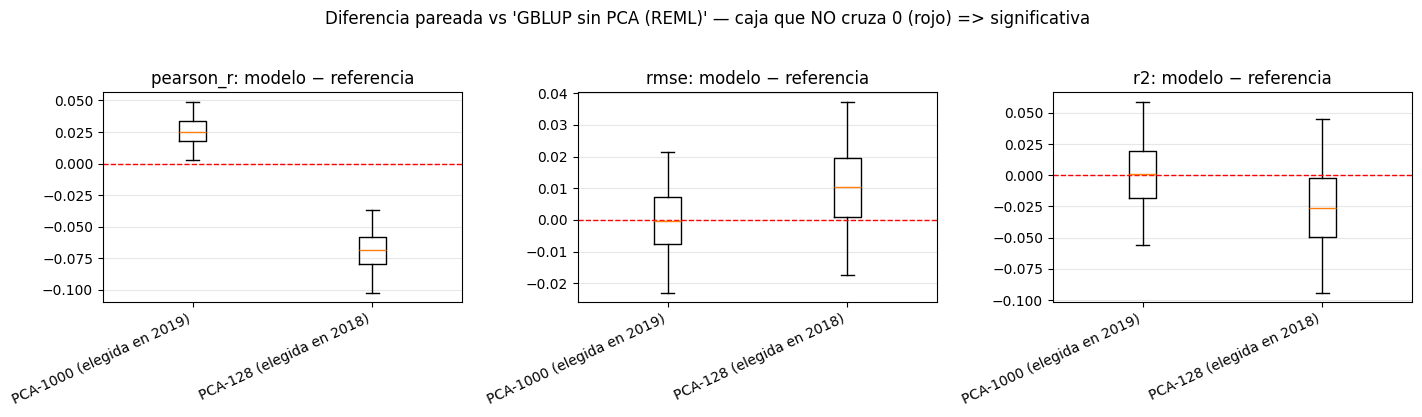

In [8]:
# === Boxplot de la DIFERENCIA pareada vs la referencia: ESTO sí mide significancia ==
# Una caja por (modelo - referencia) sobre el MISMO resample. Si la caja/bigotes
# (IC95%) NO cruzan el 0 (línea roja) => diferencia significativa. Signo: para
# Pearson/R² arriba de 0 = el modelo le gana al baseline; para RMSE es al revés.
# (Dos boxplots marginales "uno más arriba" NO alcanzan: se solapan por el ruido
#  compartido de val; la diferencia lo cancela y por eso se puede leer.)
ref = list(samples_by_model)[0]
others = list(samples_by_model)[1:]
fig, axes = plt.subplots(1, len(METRICS), figsize=(4.8 * len(METRICS), 4))
for ax, m in zip(np.atleast_1d(axes), METRICS):
    data = []
    for name in others:
        sx, sr = samples_by_model[name][m], samples_by_model[ref][m]
        n = min(len(sx), len(sr))
        d = (sx[:n] - sr[:n]); data.append(d[np.isfinite(d)])
    ax.boxplot(data, whis=(2.5, 97.5), showfliers=False)
    ax.set_xticks(range(1, len(others) + 1))
    ax.set_xticklabels(others, rotation=25, ha="right")
    ax.axhline(0, color="red", ls="--", lw=1)          # 'sin diferencia'
    ax.set_title(f"{m}: modelo − referencia")
    ax.grid(True, axis="y", alpha=0.3)
fig.suptitle(f"Diferencia pareada vs '{ref}' — caja que NO cruza 0 (rojo) => significativa", y=1.03)
fig.tight_layout()
fig.savefig(FIG_DIR / "box_paired_diff.png", dpi=150, bbox_inches="tight")
plt.show()

## Notas

- **Un solo fold**: con el split fijo (train 2017-18 / val 2019) hay un único fold
  de validación; el notebook toma ese. El test 2020 queda intocable.
- **Reproducible**: el bootstrap usa la seed del config; misma config → mismo IC.
- **Caché**: con `USE_CACHE = True` cada modelo se evalúa una sola vez por
  (config, seed, `N_BOOT`, `ALPHA`); las corridas siguientes levantan el resultado
  de `outputs/eval_cache` sin reentrenar. Cambiar un hiperparámetro del config
  invalida su entrada sola; poné `USE_CACHE = False` para forzar recómputo.
- **Modelos entrenados**: para reusar un modelo/encoder sin reentrenar, `scripts/train.py` lo guarda como wandb
  Artifact + copia local; se carga con `load_model_artifact(...)` pasando los
  `train_years` del fold para que el chequeo anti-leakage corte cualquier fuga.
- **Figuras**: se guardan en `FIG_DIR` (`experiments/figs`, gitignored)

## Autoencoder por dimensión vs GBLUP

El AE comprime los ~4.6k SNPs binarios a un latente de dimensión fija (regla 4: salida
sigmoide + BCE). Corrimos **un sweep bayesiano por dimensión** — 32 / 64 / 128 / 256 —
minimizando la **BCE de reconstrucción en 2018**. Acá traemos el **mejor AE de cada
dimensión** (`val_bce_best` mínimo) y lo probamos como compresor aguas abajo de GBLUP,
igual que PCA: el `AutoencoderReducer` **re-ajusta el AE train-only en cada fold**
(regla 1) — con la *receta* de HP del sweep, reentrenada en 2017+2018 para reportar en
val 2019 (no se reusan los pesos del sweep, que eran de 2017). Comparamos cada `AE-d`
contra el baseline GBLUP **y** contra `PCA-d` de la **misma dimensión** (no lineal vs
lineal). El test 2020 queda sellado.

In [9]:
from src.training.ae_select import best_ae_from_sweep
from src.utils.config import set_nested

GBLUP_BASE = "configs/exp_gblup_2017_2018_to_2019.yaml"   # GBLUP sin compresor (baseline, modelo[0])

# sweep_id por dimensión latente del AE (cada uno minimiza val_bce_best = BCE recon 2018).
AE_SWEEPS = {
    32:  "oromagnoli-/maze-genomic-pred/eer2osdp",
    64:  "oromagnoli-/maze-genomic-pred/2g38s9q3",
    128: "oromagnoli-/maze-genomic-pred/8lgjyjvv",
    256: "oromagnoli-/maze-genomic-pred/qj9pqf6w",
}

ae_rows, AE_CONFIGS = [], {}
for dim, sweep in AE_SWEEPS.items():
    info = best_ae_from_sweep(sweep)                # baja meta + pesos del mejor trial del sweep
    hp   = dict(info["meta"].get("ae_params", {}))  # RECETA de HP (se re-entrena train-only; los pesos del sweep eran de 2017)
    met  = info["meta"].get("metrics", {})
    assert int(hp.get("latent_dim")) == dim, (dim, hp.get("latent_dim"))
    ae_rows.append({
        "dim": dim, "run": info["run_id"],
        "val_bce_best": round(float(info["metric_value"]), 4),
        "recon_acc":    round(float(met.get("ae_val_recon_acc_best", np.nan)), 4),
        "encoder_hidden": hp.get("encoder_hidden"), "activation": hp.get("activation"),
        "lr": round(float(hp.get("lr", np.nan)), 5),
        "dropout":     round(float(hp.get("dropout", 0.0)), 3),
        "denoising_p": round(float(hp.get("denoising_p", 0.0)), 3),
        "batchnorm": hp.get("batchnorm"), "batch_size": hp.get("batch_size"),
    })
    # GBLUP sobre el embedding del AE = base GBLUP (sin pca) + bloque autoencoder. El
    # AutoencoderReducer re-ajusta el AE train-only en cada fold (regla 1): con esta
    # receta de HP, reentrenado en 2017+2018 para reportar en val 2019.
    cfg = load_config(GBLUP_BASE)
    cfg["preprocess"] = {"autoencoder": hp}
    cfg["artifacts"]  = {"save_model": False}
    AE_CONFIGS[f"AE-{dim} + GBLUP"] = cfg

ae_df = pd.DataFrame(ae_rows).sort_values("dim").reset_index(drop=True)
print("Mejor AE por dimensión (seleccionado por BCE de reconstrucción en val 2018):")
ae_df

wandb:   2 of 2 files downloaded.  
wandb:   2 of 2 files downloaded.  
wandb:   2 of 2 files downloaded.  
wandb:   2 of 2 files downloaded.  


Mejor AE por dimensión (seleccionado por BCE de reconstrucción en val 2018):


,dim,run,val_bce_best,recon_acc,encoder_hidden,activation,lr,dropout,denoising_p,batchnorm,batch_size
0,32,f14m0ycx,0.4920,0.7687,[512],leaky_relu,0.00114,0.184,0.027,True,256
1,64,pz76geun,0.4751,0.7790,[1024],elu,0.00054,0.283,0.062,True,256
2,128,xn75e6c8,0.4599,0.7897,[1024],leaky_relu,0.00052,0.252,0.014,True,128
3,256,ylkkuejq,0.4521,0.7923,[512],elu,0.00021,0.054,0.016,True,128


In [10]:
# Para cada dim agregamos el AE (no lineal) y PCA de la MISMA dimensión (lineal),
# además del baseline GBLUP sin compresión. Todo sobre el split fijo train 2017+2018
# -> val 2019, con IC95% por bootstrap cluster a nivel línea (evaluate_model + caché).
DIM_CONFIGS = {"GBLUP sin PCA (REML)": GBLUP_BASE}
for dim in AE_SWEEPS:
    DIM_CONFIGS[f"AE-{dim} + GBLUP"] = AE_CONFIGS[f"AE-{dim} + GBLUP"]
    cfg_pca = load_config(PCA_BASE); set_nested(cfg_pca, DIM_KEY, dim)
    DIM_CONFIGS[f"PCA-{dim}"] = cfg_pca

dim_rows, dim_samples = [], {}
for name, cfg in DIM_CONFIGS.items():
    r, s = evaluate_model(name, cfg)
    dim_rows.extend(r); dim_samples[name] = s
    print(f"[ok] {name}")

dim_df = pd.DataFrame(dim_rows)
# Vista de portada: Pearson (predicho-observado) por modelo, con su IC95%.
dim_df[dim_df.metric == "pearson_r"].reset_index(drop=True)

  [cache hit] GBLUP sin PCA (REML) (90f1d6fe13802d36)
[ok] GBLUP sin PCA (REML)
  [cache hit] AE-32 + GBLUP (c2bdb809451e25ea)
[ok] AE-32 + GBLUP
  [cache hit] PCA-32 (19a0d169ce4fdd12)
[ok] PCA-32
  [cache hit] AE-64 + GBLUP (181b2cfc9c1c5c83)
[ok] AE-64 + GBLUP
  [cache hit] PCA-64 (516e2862626d3a26)
[ok] PCA-64
  [cache hit] AE-128 + GBLUP (f9e96569cfde4be4)
[ok] AE-128 + GBLUP
  [cache hit] PCA-128 (d60b0cec807a233b)
[ok] PCA-128
  [cache hit] AE-256 + GBLUP (8c542a536a03ea63)
[ok] AE-256 + GBLUP
  [cache hit] PCA-256 (efffb558724d4b1d)
[ok] PCA-256


,model,metric,point,lo,hi
0,GBLUP sin PCA (REML),pearson_r,0.314528,0.246174,0.377771
1,AE-32 + GBLUP,pearson_r,0.147911,0.082886,0.213477
2,PCA-32,pearson_r,0.238452,0.168610,0.303620
3,AE-64 + GBLUP,pearson_r,0.246216,0.182337,0.307256
4,PCA-64,pearson_r,0.248804,0.182051,0.309757
5,AE-128 + GBLUP,pearson_r,0.227220,0.162695,0.291665
6,PCA-128,pearson_r,0.245375,0.180659,0.306936
7,AE-256 + GBLUP,pearson_r,0.223852,0.152229,0.291041
8,PCA-256,pearson_r,0.257733,0.192142,0.321966


In [11]:
# Diferencia PAREADA vs el baseline GBLUP (mismo resample del bootstrap): si el IC95%
# de (modelo - baseline) no cruza 0, la diferencia es significativa. Para pearson_r/r2
# >0 = el compresor le gana al baseline; para rmse <0 = le gana (menos error).
ref = "GBLUP sin PCA (REML)"
qlo, qhi = 100 * ALPHA / 2, 100 * (1 - ALPHA / 2)
for name in [k for k in dim_samples if k != ref]:
    print(f"\n{name}  -  {ref}:")
    for m in METRICS:
        sx, sr = dim_samples[name][m], dim_samples[ref][m]
        n = min(len(sx), len(sr)); d = (sx[:n] - sr[:n]); d = d[np.isfinite(d)]
        lo, hi = np.nanpercentile(d, [qlo, qhi])
        sig = "SIGNIFICATIVA" if (lo > 0 or hi < 0) else "no significativa (IC incluye 0)"
        print(f"  {m:>9}: delta = {np.mean(d):+.4f}  IC95% [{lo:+.4f}, {hi:+.4f}]  -> {sig}")
print("\nOJO: la dim se evalúa acá DIRECTO sobre val 2019; elegir la mejor dim sobre "
      "este mismo set sería optimista. La selección honesta de dim va en inner-2018 "
      "(como en la sección de PCA de arriba). 2020 sellado.")


AE-32 + GBLUP  -  GBLUP sin PCA (REML):
  pearson_r: delta = -0.1661  IC95% [-0.2204, -0.1096]  -> SIGNIFICATIVA
       rmse: delta = -0.1112  IC95% [-0.1577, -0.0678]  -> SIGNIFICATIVA
         r2: delta = +0.2746  IC95% [+0.1578, +0.4060]  -> SIGNIFICATIVA

PCA-32  -  GBLUP sin PCA (REML):
  pearson_r: delta = -0.0759  IC95% [-0.1289, -0.0192]  -> SIGNIFICATIVA
       rmse: delta = -0.0578  IC95% [-0.1003, -0.0175]  -> SIGNIFICATIVA
         r2: delta = +0.1459  IC95% [+0.0428, +0.2648]  -> SIGNIFICATIVA

AE-64 + GBLUP  -  GBLUP sin PCA (REML):
  pearson_r: delta = -0.0676  IC95% [-0.1126, -0.0202]  -> SIGNIFICATIVA
       rmse: delta = -0.0451  IC95% [-0.0833, -0.0087]  -> SIGNIFICATIVA
         r2: delta = +0.1146  IC95% [+0.0211, +0.2192]  -> SIGNIFICATIVA

PCA-64  -  GBLUP sin PCA (REML):
  pearson_r: delta = -0.0654  IC95% [-0.1135, -0.0191]  -> SIGNIFICATIVA
       rmse: delta = -0.0263  IC95% [-0.0651, +0.0114]  -> no significativa (IC incluye 0)
         r2: delta = +0.0675 

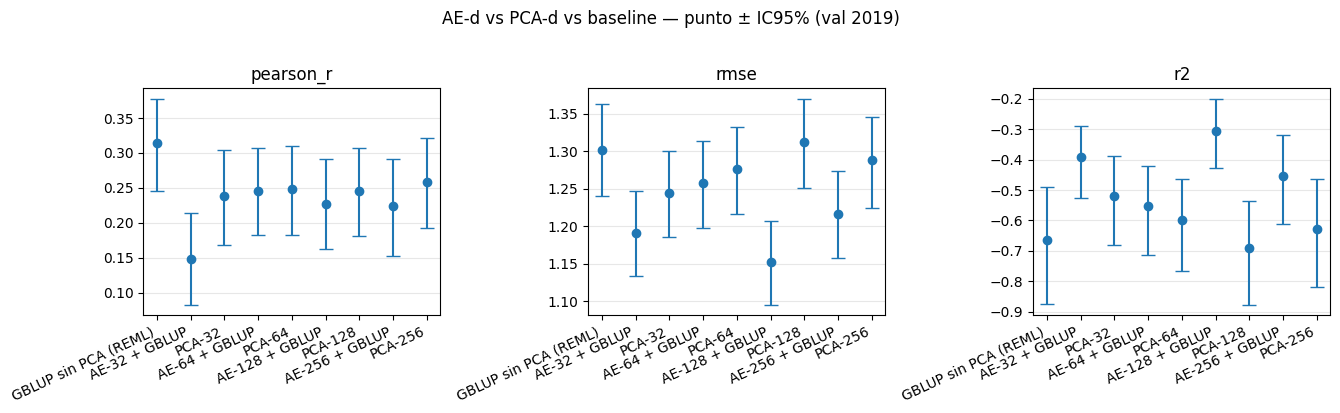

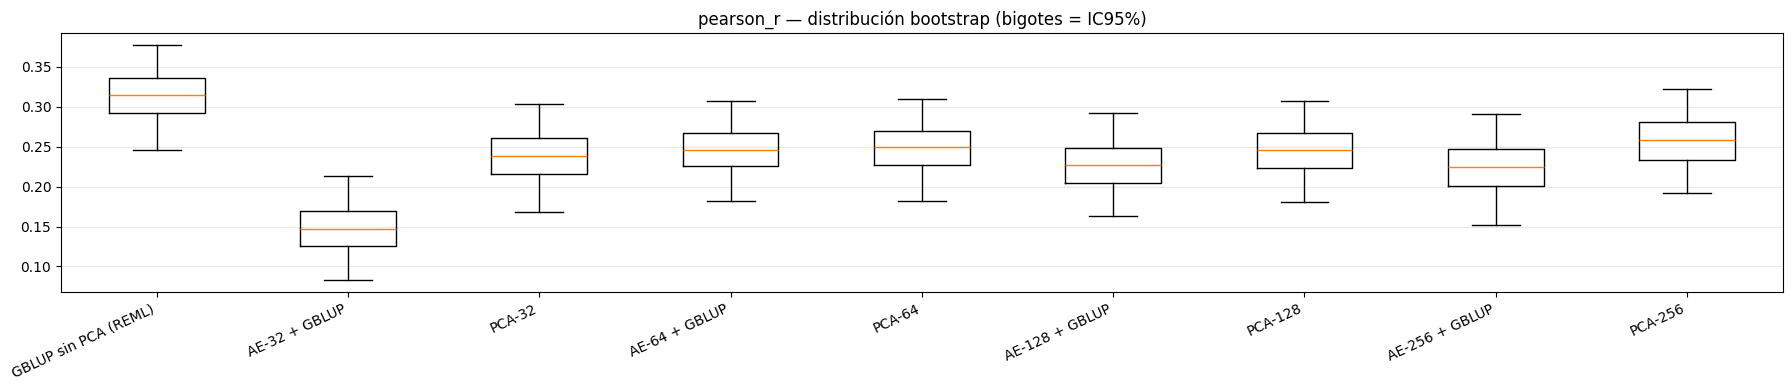

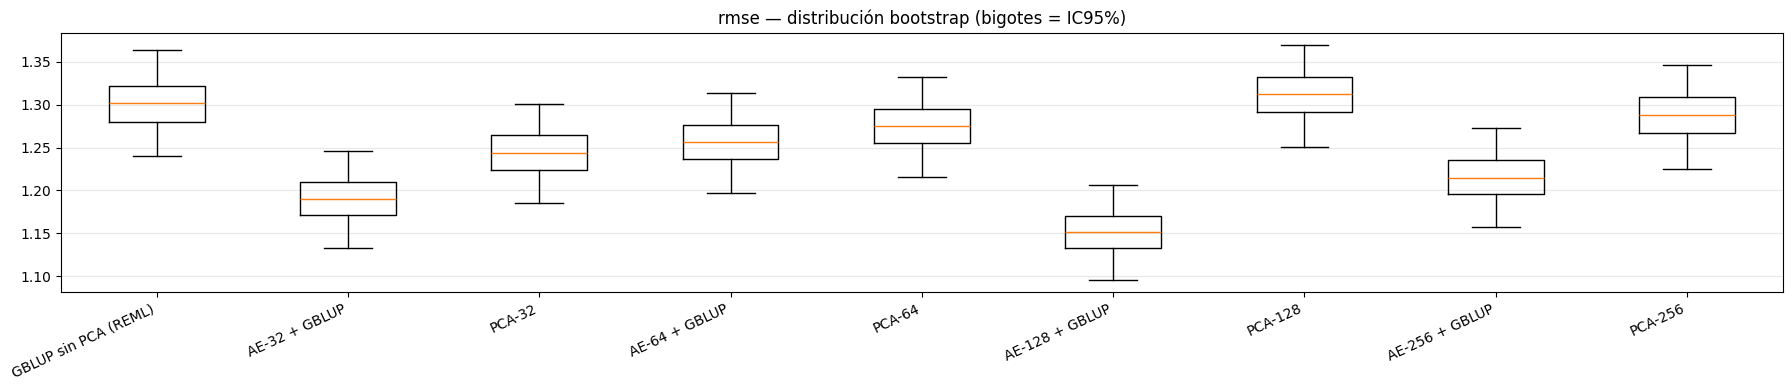

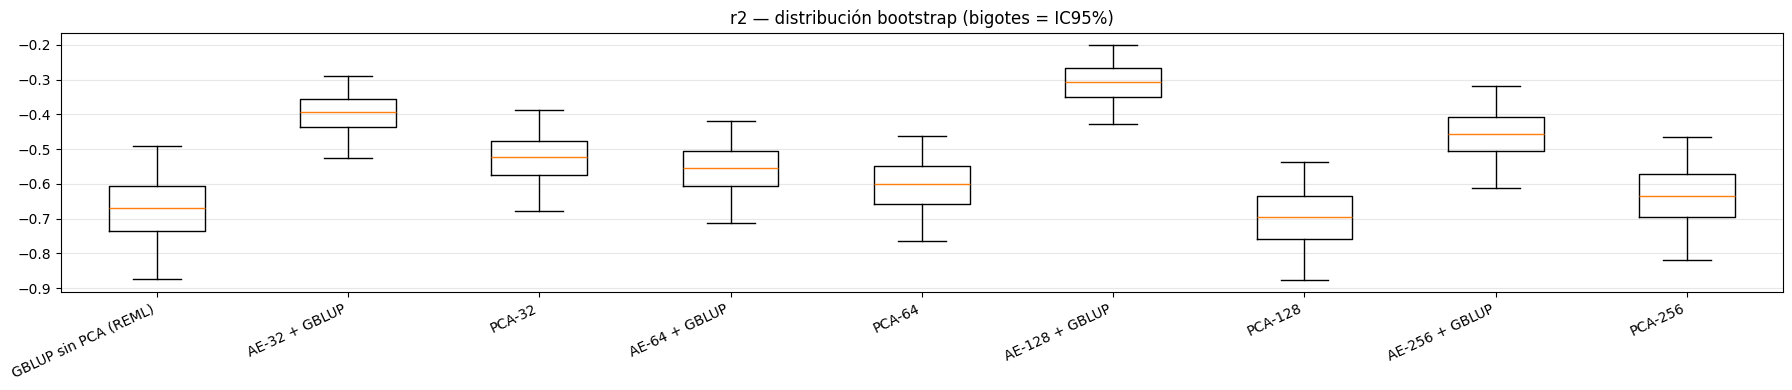

In [12]:
# Reusa los mismos gráficos de arriba sobre el set de modelos por dimensión.
fig = plot_ci(dim_df, title="AE-d vs PCA-d vs baseline — punto ± IC95% (val 2019)")
fig.savefig(FIG_DIR / "ci_errorbars_ae.png", dpi=150, bbox_inches="tight")
plt.show()

for m in METRICS:
    fig = plot_box(dim_samples, m)
    if fig is not None:
        fig.savefig(FIG_DIR / f"box_ae_{m}.png", dpi=150, bbox_inches="tight")
        plt.show()

### Lectura

**Reconstrucción (sweep).** La BCE de validación baja monótona con la dimensión
(0.492 → 0.475 → 0.460 → 0.452 para 32/64/128/256; accuracy de bits 0.77 → 0.79):
más latente reconstruye mejor, como era de esperar. Todos los ganadores usan
batchnorm, encoder de una sola capa (512/1024) y denoising/dropout suaves.

**Downstream — Pearson (métrica de portada, val 2019).** Ningún compresor le gana al
**baseline GBLUP sin comprimir** (r = 0.314): comprimir *pierde* señal de correlación.
- `AE-d` vs `PCA-d` de igual dim: **empatan en d=64** (AE 0.246 vs PCA 0.249) y **PCA
  queda por encima** en 32/128/256. El AE no lineal **no le gana a PCA** en
  correlación a ninguna dimensión.
- `AE-32` es el peor (0.148): a dimensión muy baja el cuello no lineal descarta señal
  predictiva aunque reconstruya bien.

**Downstream — RMSE / R².** Acá el AE **sí** mejora fuerte y significativo vs el
baseline: `AE-128` baja el RMSE a 1.15 (R² −0.30) contra 1.30 del baseline (R² −0.66),
ΔR² = +0.36 con IC que no cruza 0; `AE-256` y `AE-32` también mejoran RMSE/R² de forma
significativa. PCA **no** lo logra (su RMSE queda ~ baseline). El embedding del AE
**re-escala** las predicciones y reduce el error cuadrático, pero a costa del ranking
(Pearson).

**Conclusión.** La mejor reconstrucción (d=256) **no** es la que mejor predice — confirma
la decisión de tunear el AE por reconstrucción y dejar la dimensión a la selección
downstream. Con la portada en Pearson, el baseline GBLUP sigue siendo el modelo a batir
y el AE no aporta sobre PCA; el AE solo destaca en RMSE/R² (ataca la *calibración de
escala*, no el ranking). La selección honesta de dim va en inner-2018; 2020 sellado.

## XGBoost por dimensión (selección honesta 2018 → reporte 2019)

Para cada compresor corrimos un **sweep bayesiano de los HP de XGBoost** (`sweep_xgb.yaml`)
entrenando con **2017** y eligiendo por Pearson en **2018** — sin tocar 2019, así la
comparación final no sufre *winner's curse*. Acá tomamos el **mejor trial de cada
sweep**, lo **reentrenamos con 2017+2018** y lo **testeamos en 2019** con IC95% por
bootstrap, contra el baseline GBLUP. Cuatro dimensiones de AE (32/64/128/256) + un
control **PCA-128** (la mejor dim de PCA bajo selección honesta en 2018). El AE se
re-ajusta train-only por fold (regla 1). 2020 sellado.

> Nota: con un solo año de train (2017) XGBoost no puede hacer early stopping temporal,
> así que `n_estimators` fue un HP más del sweep. En el reporte se usa el valor elegido,
> reentrenando sobre 2017+2018.

In [13]:
from src.training.sweep import best_run_from_sweep

# sweep_id + config base por modelo (4 dims de AE + 1 PCA de control). El mejor trial
# de cada sweep se eligió por pearson_r_mean = Pearson en val 2018 (train 2017),
# honesto: 2019 nunca entró en la selección.
XGB_SWEEPS = {
    "XGB AE-32":   ("oromagnoli-/maze-genomic-pred/1rewf5z5", "configs/exp_xgb_ae_d32_2017_to_2018.yaml"),
    "XGB AE-64":   ("oromagnoli-/maze-genomic-pred/onke89wu", "configs/exp_xgb_ae_d64_2017_to_2018.yaml"),
    "XGB AE-128":  ("oromagnoli-/maze-genomic-pred/gz2l9qg2", "configs/exp_xgb_ae_d128_2017_to_2018.yaml"),
    "XGB AE-256":  ("oromagnoli-/maze-genomic-pred/0dbchh3l", "configs/exp_xgb_ae_d256_2017_to_2018.yaml"),
    "XGB PCA-128": ("oromagnoli-/maze-genomic-pred/dcynh8s6", "configs/exp_xgb_pca_2017_to_2018.yaml"),
}
# REPORTE honesto: HP elegidos en 2018 -> se REENTRENA con 2017+2018 y se testea en
# 2019 (val externo nunca usado para elegir). 2020 sellado.
REPORT_CV = {"scheme": "fixed_temporal", "val_year": 2019, "train_years": [2017, 2018],
             "holdout_test_year": 2020, "enforce_disjoint_lines": True}

XGB_CONFIGS = {"GBLUP sin PCA (REML)": "configs/exp_gblup_2017_2018_to_2019.yaml"}
xgb_sel = []
for name, (sweep, base) in XGB_SWEEPS.items():
    ov, p2018, rid = best_run_from_sweep(sweep)        # mejor por pearson_r_mean (val 2018)
    cfg = load_config(base)
    for k, v in ov.items():
        set_nested(cfg, k, v)                          # mejores HP de XGBoost del sweep
    cfg["cv"] = dict(REPORT_CV)                         # reentrena 2017+2018 -> testea 2019
    cfg["artifacts"] = {"save_model": False}
    XGB_CONFIGS[name] = cfg
    xgb_sel.append({
        "modelo": name, "run": rid, "pearson_val2018": round(p2018, 4),
        "n_estimators": ov.get("model.params.n_estimators"),
        "max_depth": ov.get("model.params.max_depth"),
        "lr": round(float(ov.get("model.params.learning_rate")), 4),
        "subsample": round(float(ov.get("model.params.subsample")), 3),
        "colsample": round(float(ov.get("model.params.colsample_bytree")), 3),
        "reg_lambda": round(float(ov.get("model.params.reg_lambda")), 3),
    })

xgb_sel_df = pd.DataFrame(xgb_sel)
print("Mejor trial de cada sweep (HP elegidos por Pearson en val 2018):")
xgb_sel_df

Mejor trial de cada sweep (HP elegidos por Pearson en val 2018):


,modelo,run,pearson_val2018,n_estimators,max_depth,lr,subsample,colsample,reg_lambda
0,XGB AE-32,e8zgjiq5,0.3559,1142,6,0.1253,0.644,0.836,1.145
1,XGB AE-64,oqmljr2w,0.3799,884,6,0.0190,0.551,0.946,4.370
2,XGB AE-128,iqnl4wvt,0.3934,247,6,0.0077,0.713,0.373,0.031
3,XGB AE-256,459i6sro,0.4560,499,5,0.0510,0.966,0.601,0.859
4,XGB PCA-128,8s3yclr8,0.4066,972,6,0.0061,0.850,0.627,1.267


In [14]:
# Reentrena cada mejor XGBoost con 2017+2018 y testea en 2019, con IC95% por bootstrap
# (evaluate_model + caché). Junto con el baseline GBLUP (referencia).
xgb_rows, xgb_samples = [], {}
for name, cfg in XGB_CONFIGS.items():
    r, s = evaluate_model(name, cfg)
    xgb_rows.extend(r); xgb_samples[name] = s
    print(f"[ok] {name}")

xgb_df = pd.DataFrame(xgb_rows)
# Vista de portada: Pearson por modelo en val 2019, con su IC95%.
xgb_df[xgb_df.metric == "pearson_r"].reset_index(drop=True)

  [cache hit] GBLUP sin PCA (REML) (90f1d6fe13802d36)
[ok] GBLUP sin PCA (REML)
  [cache hit] XGB AE-32 (23fe1760ba320c2f)
[ok] XGB AE-32
  [cache hit] XGB AE-64 (ec2b26324b0700d3)
[ok] XGB AE-64
  [cache hit] XGB AE-128 (a29c03d772df31ff)
[ok] XGB AE-128
  [cache hit] XGB AE-256 (2d8f0e4bb8348869)
[ok] XGB AE-256
  [cache hit] XGB PCA-128 (5d245090a9d2e6d8)
[ok] XGB PCA-128


,model,metric,point,lo,hi
0,GBLUP sin PCA (REML),pearson_r,0.314528,0.246174,0.377771
1,XGB AE-32,pearson_r,0.245219,0.179231,0.313231
2,XGB AE-64,pearson_r,0.243655,0.169732,0.306431
3,XGB AE-128,pearson_r,0.241414,0.174128,0.303107
4,XGB AE-256,pearson_r,0.253264,0.183222,0.321075
5,XGB PCA-128,pearson_r,0.236979,0.168890,0.300639


In [15]:
# Diferencia PAREADA de cada XGBoost vs el baseline GBLUP (mismo resample bootstrap):
# IC95% de (modelo - baseline) que no cruza 0 => significativa. pearson_r/r2 >0 = el
# XGBoost le gana; rmse <0 = le gana (menos error).
ref = "GBLUP sin PCA (REML)"
qlo, qhi = 100 * ALPHA / 2, 100 * (1 - ALPHA / 2)
for name in [k for k in xgb_samples if k != ref]:
    print(f"\n{name}  -  {ref}:")
    for m in METRICS:
        sx, sr = xgb_samples[name][m], xgb_samples[ref][m]
        n = min(len(sx), len(sr)); d = (sx[:n] - sr[:n]); d = d[np.isfinite(d)]
        lo, hi = np.nanpercentile(d, [qlo, qhi])
        sig = "SIGNIFICATIVA" if (lo > 0 or hi < 0) else "no significativa (IC incluye 0)"
        print(f"  {m:>9}: delta = {np.mean(d):+.4f}  IC95% [{lo:+.4f}, {hi:+.4f}]  -> {sig}")


XGB AE-32  -  GBLUP sin PCA (REML):
  pearson_r: delta = -0.0681  IC95% [-0.1341, +0.0010]  -> no significativa (IC incluye 0)
       rmse: delta = -0.1276  IC95% [-0.1804, -0.0748]  -> SIGNIFICATIVA
         r2: delta = +0.3124  IC95% [+0.1756, +0.4551]  -> SIGNIFICATIVA

XGB AE-64  -  GBLUP sin PCA (REML):
  pearson_r: delta = -0.0711  IC95% [-0.1442, -0.0033]  -> SIGNIFICATIVA
       rmse: delta = -0.0659  IC95% [-0.1208, -0.0155]  -> SIGNIFICATIVA
         r2: delta = +0.1659  IC95% [+0.0376, +0.3130]  -> SIGNIFICATIVA

XGB AE-128  -  GBLUP sin PCA (REML):
  pearson_r: delta = -0.0726  IC95% [-0.1384, -0.0092]  -> SIGNIFICATIVA
       rmse: delta = -0.1434  IC95% [-0.1909, -0.0976]  -> SIGNIFICATIVA
         r2: delta = +0.3493  IC95% [+0.2265, +0.4825]  -> SIGNIFICATIVA

XGB AE-256  -  GBLUP sin PCA (REML):
  pearson_r: delta = -0.0606  IC95% [-0.1173, -0.0073]  -> SIGNIFICATIVA
       rmse: delta = -0.0622  IC95% [-0.1047, -0.0214]  -> SIGNIFICATIVA
         r2: delta = +0.1568 

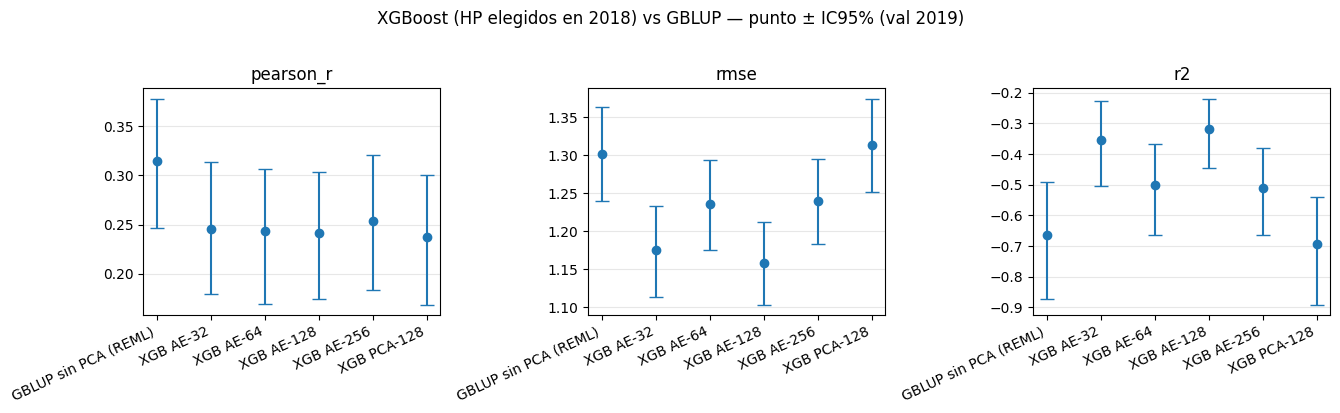

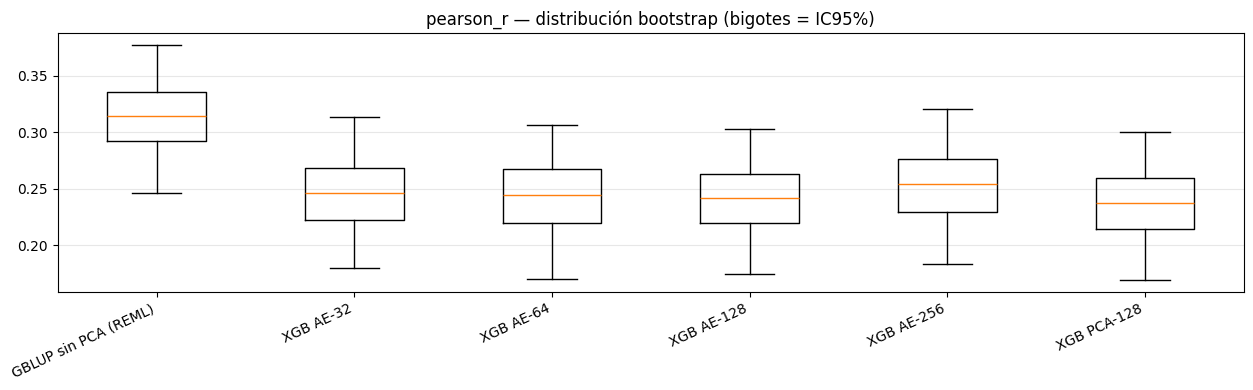

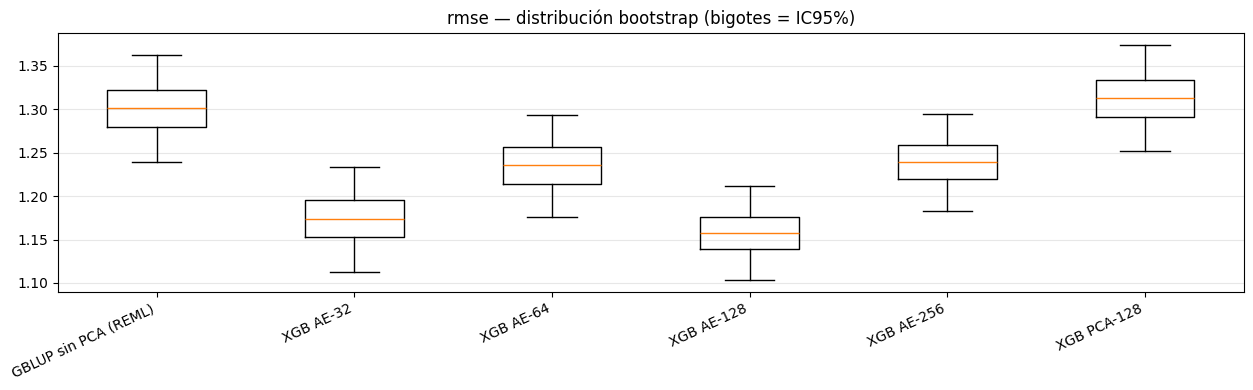

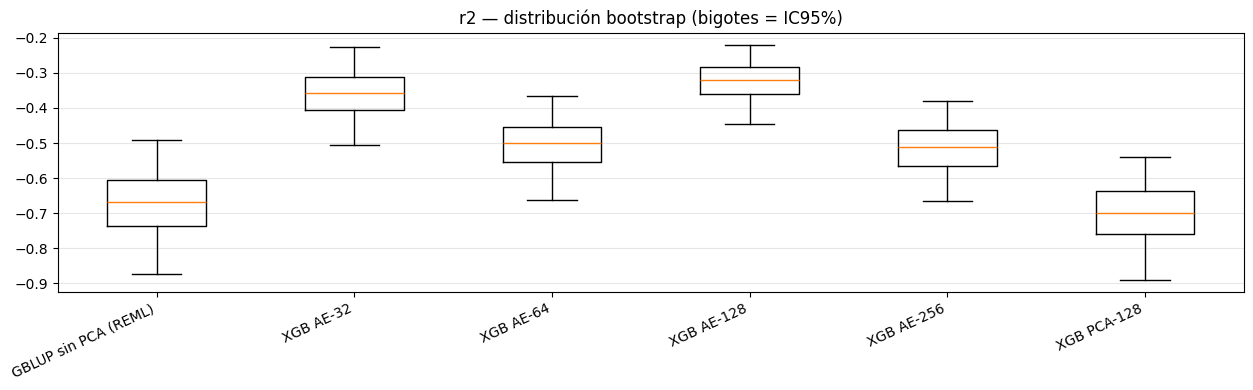

In [16]:
# Mismos gráficos sobre los XGBoost (reporte 2019) + el baseline GBLUP.
fig = plot_ci(xgb_df, title="XGBoost (HP elegidos en 2018) vs GBLUP — punto ± IC95% (val 2019)")
fig.savefig(FIG_DIR / "ci_errorbars_xgb.png", dpi=150, bbox_inches="tight")
plt.show()

for m in METRICS:
    fig = plot_box(xgb_samples, m)
    if fig is not None:
        fig.savefig(FIG_DIR / f"box_xgb_{m}.png", dpi=150, bbox_inches="tight")
        plt.show()

### Lectura

**Selección honesta (2018) → reporte (2019).** Los HP de XGBoost se eligieron por
Pearson en val 2018 (train 2017), sin tocar 2019; después se reentrenó con 2017+2018
y se reportó en 2019. La selección anduvo: `AE-256`, el mejor en 2018 (0.456), también
fue el mejor XGBoost en 2019 (0.253). En cambio `PCA-128` fue 2º en 2018 (0.407) pero
el **peor** en 2019 (0.237) — buen ejemplo de por qué 2018 (cohorte ruidosa) infla
algunos candidatos: al validar honesto en 2019 se desinfla (winner's curse evitado).

**Pearson (portada, val 2019).** **Ningún XGBoost le gana al baseline GBLUP** (0.314):
todos quedan en ~0.24–0.25 (deltas vs GBLUP negativos, significativos salvo `AE-32`,
marginal). Comprimir + árboles no recupera la correlación que GBLUP saca del genotipo
completo.

**AE vs PCA para XGBoost.** En Pearson están **empatados** (~0.24); el AE no le gana a
PCA. Pero en **RMSE / R² el AE mejora fuerte y significativo** vs el baseline (`AE-128`:
R² −0.32 vs −0.66, ΔR²=+0.35; `AE-256`/`AE-32`/`AE-64` también SIG), mientras `PCA-128`
**no** (ΔRMSE/ΔR² no significativos). Mismo patrón que con GBLUP: el embedding del AE
re-escala las predicciones (calibración), no el ranking.

**Conclusión.** Con la portada en Pearson, el **baseline GBLUP sigue siendo el modelo a
batir**: ni XGBoost ni el AE aportan sobre él en correlación. XGBoost sobre embedding
denso (~32–256 dims) no aventaja a GBLUP lineal para el efecto aditivo. El AE solo
destaca en RMSE/R². Adjudicación final: 2020 (sellado).